1. Preparación

Traemos las herramientas del programa: una para las tablas, otra para los cálculos y otras para los gráficos.

In [1]:
import numpy as np                 # sirve para hacer cálculos con números
import pandas as pd                # sirve para trabajar con tablas
import matplotlib.pyplot as plt    # sirve para hacer gráficos
import seaborn as sns              # hace los gráficos más bonitos

sns.set_theme(style="whitegrid")   # le pone fondo con cuadrícula a los gráficos

2Cargar los datos

Qué se analiza: abrimos el archivo de casos de dengue y clima del país y vemos cuántas filas y columnas tiene. Cada fila es una semana. Le decimos al programa que la columna de fechas es una fecha de verdad (no un texto), para poder hacer gráficos del tiempo.

In [2]:
df = pd.read_csv("../data/raw/vectoria_dengue_nacional_real.csv",
                 parse_dates=["fecha_inicio_semana"])   # abre el archivo y reconoce la columna de fechas
print(df.shape)                                         # muestra (filas, columnas)

(574, 12)


3. Primer vistazo

Qué se analiza: miramos las primeras filas y el tipo de cada columna para entender qué tenemos:

fecha_inicio_semana, anio, semana_epi: cuándo es la semana.
provincia, region_climatica, poblacion: datos del país (son iguales en todas las filas).
casos_dengue: casos de dengue en la semana. Es lo que queremos predecir.
tasa_100k: casos por cada 100,000 personas.
lluvia_mm, temp_max_c, temp_min_c, humedad_rel_pct: el clima de la semana.

In [3]:
df.head()    # muestra las primeras 5 filas

,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2013-12-29,2014,1,Costa Rica,Nacional,5170000,239,4.62,11.0,27.2,19.9,84.9
1,2014-01-05,2014,2,Costa Rica,Nacional,5170000,257,4.97,8.9,27.0,19.7,83.8
2,2014-01-12,2014,3,Costa Rica,Nacional,5170000,184,3.56,4.5,27.1,19.5,81.7
3,2014-01-19,2014,4,Costa Rica,Nacional,5170000,156,3.02,7.7,27.1,19.5,80.0
4,2014-01-26,2014,5,Costa Rica,Nacional,5170000,189,3.66,4.7,27.2,18.7,78.0


In [4]:
df.info()    # muestra el tipo de cada columna y cuántos datos tiene

<class 'pandas.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   fecha_inicio_semana  574 non-null    datetime64[us]
 1   anio                 574 non-null    int64         
 2   semana_epi           574 non-null    int64         
 3   provincia            574 non-null    str           
 4   region_climatica     574 non-null    str           
 5   poblacion            574 non-null    int64         
 6   casos_dengue         574 non-null    int64         
 7   tasa_100k            574 non-null    float64       
 8   lluvia_mm            574 non-null    float64       
 9   temp_max_c           574 non-null    float64       
 10  temp_min_c           574 non-null    float64       
 11  humedad_rel_pct      574 non-null    float64       
dtypes: datetime64[us](1), float64(5), int64(4), str(2)
memory usage: 53.9 KB


Qué encontramos: la primera fila es la semana del 29 de diciembre de 2013, con 239 casos. Parece raro que sea 2013 si dice anio = 2014. No es un error: las semanas epidemiológicas (semana_epi) pueden empezar en los últimos días del año anterior. Las columnas de números aparecen como int64 o float64, y las de texto como object o str. Todas muestran 574 datos, así que a simple vista no falta nada.

Qué se analiza: antes de analizar, revisamos que los datos estén sanos:

¿Hay casillas vacías?
¿Hay filas repetidas?
¿Las semanas avanzan siempre de 7 en 7 días, sin saltos?
¿Hay columnas que siempre tengan el mismo valor? No sirven para predecir nada.
¿tasa_100k dice lo mismo que casos_dengue?

In [5]:
print("Casillas vacías por columna:")
print(df.isna().sum())                                # cuenta las casillas vacías de cada columna

print("Filas repetidas:", df.duplicated().sum())      # cuenta filas idénticas

# Si todo está bien, cada semana debe estar 7 días después de la anterior
saltos = df["fecha_inicio_semana"].diff().dropna()    # días entre una semana y la siguiente
print("Saltos distintos a 7 días:", (saltos != pd.Timedelta(days=7)).sum())

# Cuántos valores distintos tienen estas columnas (si es 1, siempre es lo mismo)
print(df[["provincia", "region_climatica", "poblacion"]].nunique())

# Qué tanto se parecen casos y tasa (1 = idénticos)
print("Parecido casos vs tasa:", round(df["casos_dengue"].corr(df["tasa_100k"]), 4))

Casillas vacías por columna:
fecha_inicio_semana    0
anio                   0
semana_epi             0
provincia              0
region_climatica       0
poblacion              0
casos_dengue           0
tasa_100k              0
lluvia_mm              0
temp_max_c             0
temp_min_c             0
humedad_rel_pct        0
dtype: int64
Filas repetidas: 0
Saltos distintos a 7 días: 0
provincia           1
region_climatica    1
poblacion           1
dtype: int64
Parecido casos vs tasa: 1.0


Qué encontramos:

Casillas vacías: cero en todas las columnas.
Filas repetidas: cero.
Saltos distintos a 7 días: cero, así que no falta ninguna semana.
Columnas constantes: provincia, region_climatica y poblacion tienen 1 solo valor. Siempre dicen “Costa Rica”, “Nacional” y 5,170,000. No aportan nada.
Casos vs tasa: el parecido es 1.0. La tasa es casi lo mismo que los casos dividido por una cifra fija, así que sobra.

Conclusión: los datos ya vienen limpios. Solo hay que quitar columnas inútiles.

5. Quitar columnas que sobran

Qué se hace: eliminamos las 4 columnas que no aportan: 3 siempre valen lo mismo y 1 repite la información de los casos. Además, ponemos la fecha como “etiqueta” de cada fila (índice), lo que facilita los gráficos del tiempo.

In [6]:
df = df.drop(columns=["provincia", "region_climatica", "poblacion", "tasa_100k"])  # quita las 4 columnas
df = df.set_index("fecha_inicio_semana")                                          # la fecha pasa a ser la etiqueta de cada fila
df.info()                                                                         # comprobamos cómo quedó

<class 'pandas.DataFrame'>
DatetimeIndex: 574 entries, 2013-12-29 to 2024-12-22
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   anio             574 non-null    int64  
 1   semana_epi       574 non-null    int64  
 2   casos_dengue     574 non-null    int64  
 3   lluvia_mm        574 non-null    float64
 4   temp_max_c       574 non-null    float64
 5   temp_min_c       574 non-null    float64
 6   humedad_rel_pct  574 non-null    float64
dtypes: float64(4), int64(3)
memory usage: 35.9 KB


Qué encontramos: quedan 7 columnas (anio, semana_epi, casos_dengue y las 4 del clima) y 574 filas, con fechas del 2013-12-29 al 2024-12-22.

6. Resumen en números

Qué se analiza: vemos para cada columna el promedio, el valor más bajo, el más alto y los valores “del medio”. Sirve para tener una idea de qué tan grandes son los números y si hay valores raros.

In [7]:
clima = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]   # lista con las columnas del clima
df[["casos_dengue"] + clima].describe().round(1)                       # resumen de casos y clima

,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
count,574.0,574.0,574.0,574.0,574.0
mean,268.6,52.0,27.8,21.1,83.7
std,304.2,57.6,1.7,0.9,7.7
min,12.0,0.0,24.4,18.4,61.8
25%,71.0,13.6,26.7,20.5,79.4
50%,156.0,38.5,27.4,21.2,86.7
75%,328.0,75.4,28.7,21.8,89.3
max,1749.0,625.2,33.0,23.2,94.9


Análisis:

Casos: el promedio (269) es mucho más alto que la mediana (156). Eso quiere decir que hay pocas semanas con muchísimos casos que “jalan” el promedio hacia arriba. El máximo (1,749) es más de 6 veces el promedio.
Lluvia: pasa lo mismo, con promedio 52 mm y máximo de 625 mm. Hay semanas con lluvia extrema. También hay semanas con 0 mm.
Temperaturas: casi no cambian: la máxima va de 24 a 33 °C y la mínima de 18 a 23 °C. Son rangos chicos, pero ya veremos que ese cambio pequeño importa.
Humedad: siempre es alta (promedio 84 %), como corresponde a un país tropical.

7. Casos de dengue a través del tiempo

Qué se analiza: dibujamos cuántos casos hubo cada semana y cuántos por año. Así vemos los brotes: épocas en que los casos se disparan mucho más de lo normal.

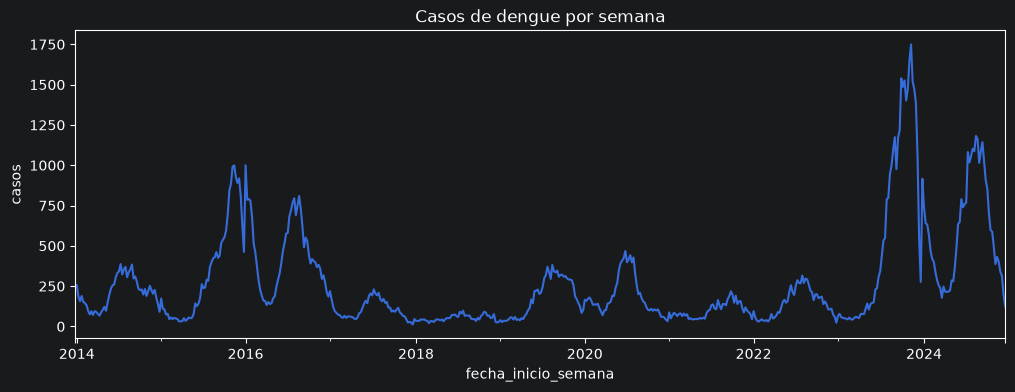

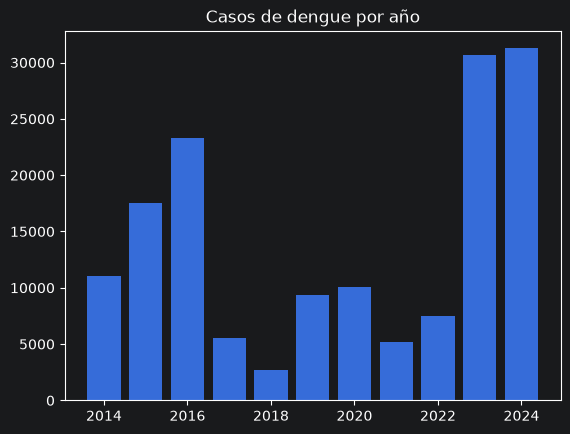

In [8]:
df["casos_dengue"].plot(figsize=(12, 4), title="Casos de dengue por semana")   # línea de casos por semana
plt.ylabel("casos")                                                            # nombre del eje vertical
plt.show()

por_anio = df.groupby("anio")["casos_dengue"].sum()   # suma los casos de cada año
plt.bar(por_anio.index, por_anio.values)              # una barra por año
plt.title("Casos de dengue por año")
plt.show()

ráfico de líneas: se ven subidas y bajadas que se repiten cada año, y tres picos muy altos. El mayor es de 1,749 casos en la semana del 12 de noviembre de 2023.
Análisis:

Hay tres años de brote: 2016, 2023 y 2024. 2023 y 2024 son los peores, con más de 30,000 casos cada uno, casi 6 veces los de un año bajo como 2021.
El año más bajo es 2018 (2,735 casos) y el más alto, 2024 (31,259).
Después de cada brote los casos bajan mucho (2016 → 2017 y 2018). Esto tiene sentido: tras un brote, mucha gente ya tuvo la enfermedad.
Para un modelo que predice casos, esto es un reto: los brotes son poco frecuentes y mucho más grandes que lo normal.

8. ¿Cómo se reparten los casos?

Qué se analiza: dibujamos cuántas semanas tuvieron pocos casos y cuántas tuvieron muchos. Luego lo repetimos aplicando el logaritmo, un truco matemático que achica los números muy grandes para que los brotes no tapen todo lo demás. Lo usaremos para comparar casos con clima.

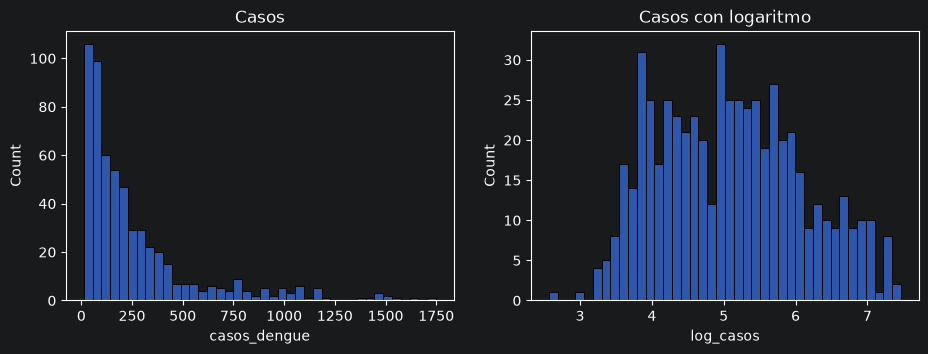

Desparejo, casos: 2.17
Desparejo, con logaritmo: 0.23


In [9]:
df["log_casos"] = np.log1p(df["casos_dengue"])   # crea una columna nueva con los casos "achicados"

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))                  # espacio para 2 gráficos lado a lado
sns.histplot(df["casos_dengue"], bins=40, ax=ejes[0])              # gráfico de los casos normales
ejes[0].set_title("Casos")
sns.histplot(df["log_casos"], bins=40, ax=ejes[1])                 # gráfico de los casos achicados
ejes[1].set_title("Casos con logaritmo")
plt.show()

# Qué tan desparejo está cada gráfico (0 = parejo)
print("Desparejo, casos:", round(df["casos_dengue"].skew(), 2))
print("Desparejo, con logaritmo:", round(df["log_casos"].skew(), 2))

El primer gráfico tiene muchas barras altas a la izquierda y una “cola” larga hacia la derecha. El segundo se ve más parejo y en forma de campana. El número de “desparejo” baja de 2.17 a 0.23.

Análisis: casi todas las semanas tienen pocos casos (menos de 330) y muy pocas tienen muchísimos. Con el logaritmo esa diferencia se reduce y los datos quedan más fáciles de comparar. Por eso en los pasos 11 y 12 usamos log_casos.

9. Casos según el mes del año

Qué se analiza: vemos si los casos suben en ciertos meses. Cada caja muestra cómo se comportaron los casos de ese mes en todos los años. La línea del medio es el valor típico.

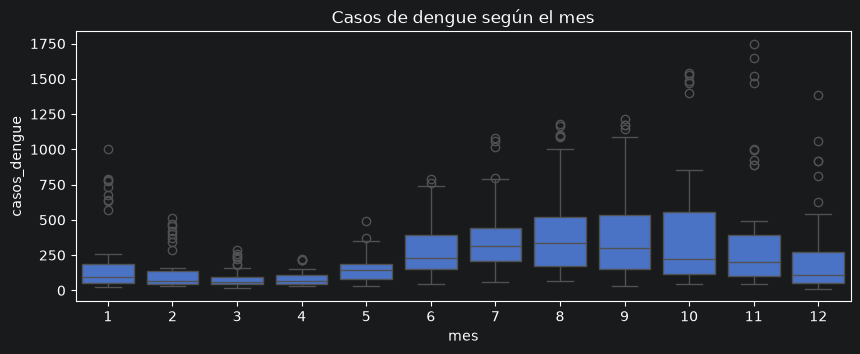

mes
1     213.0
2     132.0
3      89.0
4      86.0
5     153.0
6     287.0
7     383.0
8     431.0
9     412.0
10    406.0
11    389.0
12    236.0
Name: casos_dengue, dtype: float64


In [10]:
df["mes"] = df.index.month                 # saca el número del mes (1 a 12) de la fecha

plt.figure(figsize=(10, 3.5))
sns.boxplot(data=df, x="mes", y="casos_dengue")   # una caja por mes
plt.title("Casos de dengue según el mes")
plt.show()

print(df.groupby("mes")["casos_dengue"].mean().round(0))   # promedio de casos de cada mes

Análisis: el dengue tiene una época fija en el año. Los casos son más bajos en marzo y abril (unos 86 a 89 por semana) y suben desde mayo y junio, cuando empiezan las lluvias. El punto más alto es agosto (431), y se mantiene alto hasta noviembre. Después baja en diciembre. Esto quiere decir que el modelo puede aprender que las semanas de julio a noviembre son de riesgo, y que semana_epi es una columna útil.

10. Clima: ¿hay valores muy raros?

Qué se analiza: dibujamos una caja por cada variable del clima. Los puntitos sueltos fuera de la caja son valores muy distintos al resto (llamados valores atípicos). Después vemos las 5 semanas más lluviosas para saber si son errores o eventos reales.

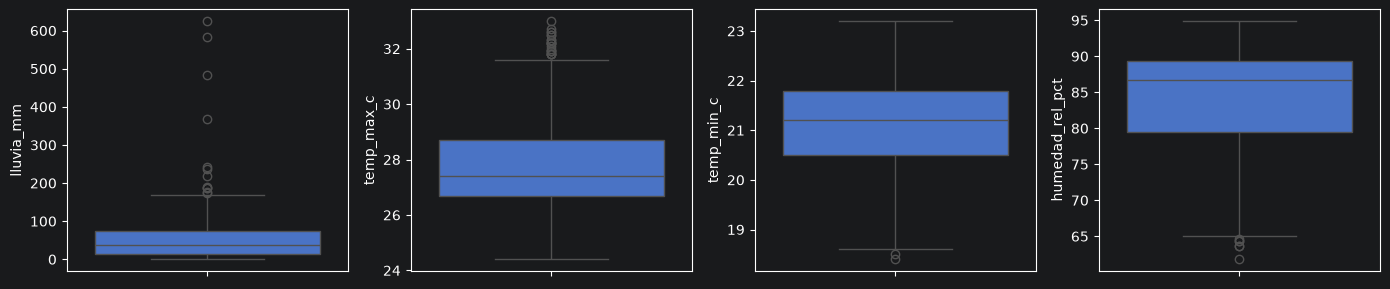

In [11]:
fig, ejes = plt.subplots(1, 4, figsize=(14, 3))     # espacio para 4 gráficos
for eje, variable in zip(ejes, clima):              # repite para cada variable del clima
    sns.boxplot(y=df[variable], ax=eje)             # dibuja su caja
plt.tight_layout()                                  # acomoda los gráficos para que no se encimen
plt.show()

In [12]:
df.nlargest(5, "lluvia_mm")[["lluvia_mm", "casos_dengue"]]   # las 5 semanas con más lluvia

,lluvia_mm,casos_dengue
fecha_inicio_semana,,
2024-05-26,625.2,489
2020-11-01,583.6,106
2024-11-10,483.4,387
2017-10-01,368.0,98
2024-06-02,242.4,636


La lluvia tiene 12 puntos sueltos, la temperatura máxima 21, la humedad 6 y la temperatura mínima solo 2.
Análisis: son lluvias enormes, pero no son errores. Según el LEEME, coinciden con el huracán Nate (octubre 2017), Eta (noviembre 2020) y la tormenta Sara (noviembre 2024). Por eso no las borramos: son parte de la realidad. Nota también que una semana con muchísima lluvia no trajo muchos casos al instante (por ejemplo, 106 casos en la de Eta). Eso sugiere que la lluvia hace efecto semanas después, y lo comprobamos en el paso 12.

11. ¿Qué tanto se relaciona el clima con los casos?

Qué se analiza: el gráfico de colores muestra qué tanto “suben juntas” dos columnas. Un número cerca de 1 quiere decir que cuando una sube, la otra también. Cerca de 0, que no tienen que ver. Negativo, que cuando una sube la otra baja. Aquí todavía comparamos el clima de la misma semana que los casos.

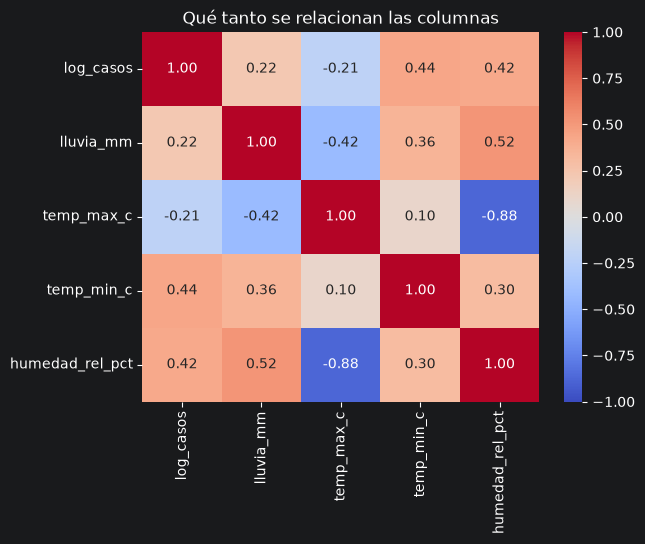

In [13]:
sns.heatmap(df[["log_casos"] + clima].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Qué tanto se relacionan las columnas")
plt.show()

Análisis:

Ninguna relación es fuerte. La mejor es la temperatura mínima (0.44): las noches más cálidas se asocian con más casos.
La temperatura máxima sale negativa, algo que parece raro. Más abajo vemos por qué.
Hay una relación casi opuesta entre temp_max_c y humedad_rel_pct (-0.88): cuando hace más calor de día, la humedad baja. Dicen casi lo mismo, así que no necesitamos fijarnos en las dos.
Una relación débil aquí no significa que el clima no sirva. Falta ver el efecto con retraso.

12. El efecto con retraso

Qué se analiza: el mosquito necesita tiempo para reproducirse y para que la gente se enferme, así que el clima de hoy afecta los casos de semanas después. Comparamos los casos con el clima de hace 0, 1, 2... hasta 12 semanas, y vemos en qué retraso la relación es más fuerte.

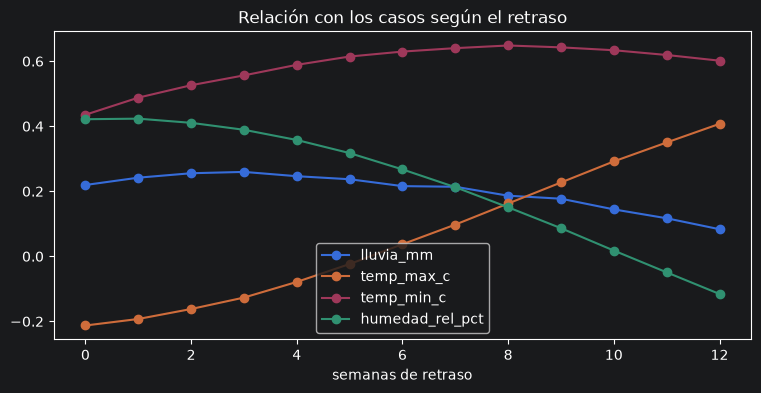

Retraso con mejor relación:
 lluvia_mm           3
temp_max_c         12
temp_min_c          8
humedad_rel_pct     1
dtype: int64
Qué tan fuerte es:
 lluvia_mm          0.26
temp_max_c         0.41
temp_min_c         0.65
humedad_rel_pct    0.42
dtype: float64


In [15]:
retrasos = range(0, 13)    # de 0 a 12 semanas de retraso

# Para cada variable del clima, mueve la columna k semanas y la compara con los casos
tabla = pd.DataFrame(
    {v: [df["log_casos"].corr(df[v].shift(k)) for k in retrasos] for v in clima},
    index=retrasos)

tabla.plot(marker="o", figsize=(9, 4), title="Relación con los casos según el retraso")
plt.xlabel("semanas de retraso")
plt.show()

print("Retraso con mejor relación:\n", tabla.idxmax())   # en qué semana es más fuerte
print("Qué tan fuerte es:\n", tabla.max().round(2))

Análisis:

La temperatura mínima es la mejor pista. Al compararla con el retraso correcto sube de 0.44 a 0.65. Se hace más fuerte desde la semana 0 hasta la 8, y después empieza a bajar. Es decir, las noches cálidas de hace unos 2 meses ayudan a explicar los casos de hoy.
La lluvia es una relación débil (0.26) con 3 semanas de retraso.
La humedad es mejor sin retraso o con 1 semana, y se pierde pasadas unas 8 semanas.
Con temp_max_c, el número mejor cae en el límite de la gráfica (12 semanas), así que no sirve para sacar conclusiones. Probablemente se explique porque el calor del día es máximo en la época seca y 12 semanas después llega la época de más casos, o sea, que es el efecto del calendario y no que el calor cause los casos.
El LEEME del profesor menciona r ≈ 0.71 con 6 semanas. Mi cálculo da 0.65 con 8 semanas porque usa un método un poco distinto (log(1 + casos) y retrasos simples). Ambos coinciden en lo importante: la temperatura mínima es la mejor pista, con un retraso de unas 6 a 8 semanas.

13. Preparación de los datos

Qué se hace: como el clima actúa con retraso, creamos columnas nuevas con el clima de 2, 4, 6 y 8 semanas atrás. Las primeras 8 semanas quedan sin esos datos (no hay clima “anterior”), así que se quitan. Guardamos el resultado en data/processed/ para usarlo en el modelo.

In [16]:
for v in clima:                              # para cada variable del clima
    for k in [2, 4, 6, 8]:                   # y para cada retraso
        df[f"{v}_lag{k}"] = df[v].shift(k)   # crea una columna con el clima de hace k semanas

df = df.dropna()                             # quita las primeras 8 semanas, que quedaron vacías
df.to_csv("../data/processed/dengue_procesado.csv")   # guarda el resultado
print(df.shape)

(566, 25)


Unas conclusiones:
Los datos del país están limpios: 574 semanas, sin casillas vacías, sin repetidos y sin semanas faltantes. Solo se quitaron 4 columnas que sobraban.

Hubo tres brotes de dengue: 2016, 2023 y 2024. Los de 2023 y 2024 son los más grandes (más de 30,000 casos al año).

Los casos siguen una época del año: bajos en marzo y abril, y más altos de julio a noviembre (agosto es el pico).

Pocas semanas tienen muchísimos casos, por eso usamos el logaritmo para compararlos.

Las lluvias extremas son eventos reales (huracanes y tormentas), así que no se eliminaron.

El clima actúa con retraso: la temperatura mínima es la mejor pista, con 6 a 8 semanas de diferencia.

Siguiente paso: usar estos datos para el modelo que predice los casos de las próximas 4 semanas.

15. Cargar los datos

Qué se analiza: abrimos el archivo y miramos cómo es. Cada fila es una semana con un pronóstico, el clima y la acción recomendada. Lo que queremos que el modelo aprenda a adivinar es la columna recomendacion.

Qué significa cada columna:

escenario: del 1 al 5, son 5 versiones de la misma semana (ya vemos por qué).
casos_pred_4sem: casos que se “predicen” para las próximas 4 semanas (simulado).
casos_umbral_endemico: cantidad “normal” de casos para esa época. Si se pasa de ahí, preocupa.
lluvia_14d_mm: lluvia de los últimos 14 días.
temp_max, temp_min, humedad: el clima de la semana.
aegypti_detectado: 1 si se detectó el mosquito Aedes aegypti en una foto (simulado), 0 si no.
recomendacion: la acción a tomar.

In [17]:
acc = pd.read_csv("../data/raw/vectoria_acciones.csv", parse_dates=["fecha_inicio_semana"])   # abre el archivo
print(acc.shape)    # (filas, columnas)
acc.head()          # primeras 5 filas

(2060, 12)


,fecha_inicio_semana,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
0,2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
1,2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2,2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
3,2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
4,2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal


In [18]:
acc.info()    # tipo de cada columna y cuántos datos tiene

<class 'pandas.DataFrame'>
RangeIndex: 2060 entries, 0 to 2059
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   fecha_inicio_semana    2060 non-null   datetime64[us]
 1   anio                   2060 non-null   int64         
 2   semana_epi             2060 non-null   int64         
 3   escenario              2060 non-null   int64         
 4   casos_pred_4sem        2060 non-null   int64         
 5   casos_umbral_endemico  2060 non-null   int64         
 6   lluvia_14d_mm          2060 non-null   float64       
 7   temp_max               2060 non-null   float64       
 8   temp_min               2060 non-null   float64       
 9   humedad                2060 non-null   float64       
 10  aegypti_detectado      2060 non-null   int64         
 11  recomendacion          2060 non-null   str           
dtypes: datetime64[us](1), float64(4), int64(6), str(1)
memory usage: 193.3 KB